# Prvi zadatak



Na početku dodavanje biblioteka

In [72]:
import numpy as np
import cv2
import os
import seaborn as sns
import matplotlib.pyplot as plt
from skimage import io
from skimage import util
from skimage import color
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from skimage import measure


Funkcija za obradu slike

In [73]:
def image_edit(image):
    # prebacivanje slike u HSV color sistem
    image_hsv = color.rgb2hsv(image)

    # za pod a)
    # prikaz originalne slike i u HSV color sistemu
    #fig, ax = plt.subplots(2, 2, figsize=(12,9), dpi=80);
    #plt.tight_layout();
    #ax[0,0].imshow(image); ax[0,0].set_title('RGB', fontsize=14);
    #ax[0,1].imshow(image_hsv[:,:,2], vmin=0, vmax=1, cmap='gray'); ax[0,1].set_title('V', fontsize=14);
    #ax[1,0].imshow(image_hsv[:,:,1], vmin=0, vmax=1, cmap='gray'); ax[1,0].set_title('S', fontsize=14);
    #ax[1,1].imshow(image_hsv[:,:,0], vmin=0, vmax=1, cmap='gray'); ax[1,1].set_title('H', fontsize=14);
    
    H = image_hsv[:,:,0]
    S = image_hsv[:,:,1]
    V = image_hsv[:,:,2]

    # formiranje maske zelene boje
    mask = (H > 0.03) & (H < 0.15) & (S > 0.2) & (S < 0.7) & (V > 0.4)
    
    # prikaz maske
    #fig2, ax2 = plt.subplots(figsize=(10,5))
    #ax2.imshow(mask, cmap='gray')
    #ax2.set_title('Maska ruke', fontsize=14)
    #ax2.axis('off')

    # izdvajanje samo maske (ruke u nasem slucaju)
    coords = np.argwhere(mask)
    y0, x0 = coords.min(axis=0)
    y1, x1 = coords.max(axis=0)

    # sečemo sliku na osnovu koordinata
    cropped = mask[y0:y1, x0:x1]

    # prikaz isečene slike
    #fig3, ax3 = plt.subplots(figsize=(10,5))
    #ax3.imshow(cropped, cmap='gray')
    #ax3.set_title('Isečena slika - scissors', fontsize=14)
    #ax3.axis('off') 

    return cropped 

In [74]:
# za testiranje i slike pod a)
#image = io.imread('/Users/jelenacicvaric/Desktop/PO/Prvi domaci/Rock Paper Scissors/scissors/0zoQAmDFXehOZsAp.png')
#cropped = image_edit(image)

Funkcija za obeležja

In [75]:
from email.mime import image


def feature_extraction(image):
    # matrica obeležja i dimenzije ulazne slike
    features = np.zeros((3,))
    M, N = image.shape

    # obeležje 1 -> odnos crnih i belih piksela u levoj polovini slike
    left_half = image[:, :N//2]
    white = np.sum(left_half == 1) # za ruku
    black = np.sum(left_half == 0) # za pozadinu
    if white == 0:
        ratio = float('inf') 
    else:
        ratio = black / white
    features[0] = ratio

    # obeležje 2 -> odnos dimenzija slike
    features[1]=N/M

    # obeležje 3 -> odnos crnih i belih piksela u levoj četvrtini slike
    left_q = image[:, N//4]
    number = 0
    for i in range(1, M):
        if left_q[i] == 1:
            number += 1
    features[2] = number
        

    return features
    

Smeštanje obeležja u matricu i učitavanje svih slika

In [76]:
dataset_dir = os.path.join(os.getcwd(), "Rock Paper Scissors")

folder_rock = os.path.join(dataset_dir, "rock")
folder_paper = os.path.join(dataset_dir, "paper")
folder_scissors = os.path.join(dataset_dir, "scissors")

rock = []
paper = []
scissors = []


for filename in os.listdir(folder_rock):
    image_path = os.path.join(folder_rock, filename)
    img = util.img_as_float(io.imread(image_path))
    img_cropped = image_edit(img)
    rock.append(feature_extraction(img_cropped))

for filename in os.listdir(folder_paper):
    image_path = os.path.join(folder_paper, filename)
    img = util.img_as_float(io.imread(image_path))
    img_cropped = image_edit(img)
    paper.append(feature_extraction(img_cropped))

for filename in os.listdir(folder_scissors):
    image_path = os.path.join(folder_scissors, filename)
    img = util.img_as_float(io.imread(image_path))
    img_cropped = image_edit(img)
    scissors.append(feature_extraction(img_cropped))

Prikaz obeležja

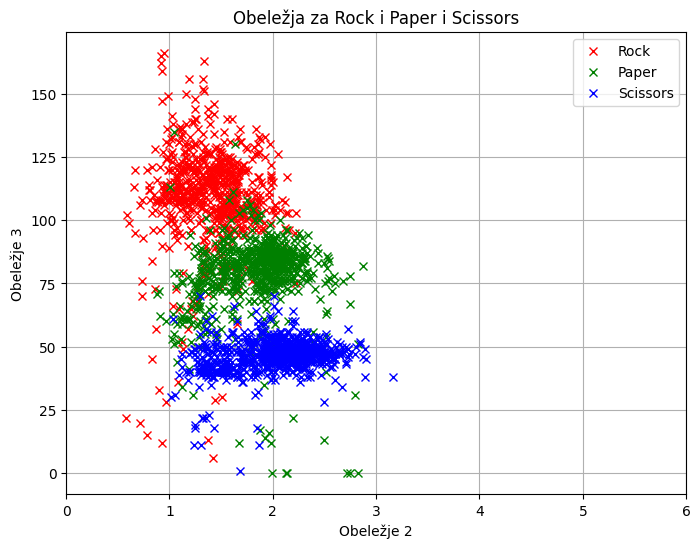

In [100]:
rock_array = np.array(rock).T  
paper_array = np.array(paper).T 
scissors_array = np.array(scissors).T

plt.figure(figsize=(8, 6))
plt.plot(rock_array[1, :], rock_array[2, :], 'rx', label='Rock')  
plt.plot(paper_array[1, :], paper_array[2, :], 'gx', label='Paper')  
plt.plot(scissors_array[1, :], scissors_array[2, :], 'bx', label='Scissors') 

plt.xlabel('Obeležje 2')
plt.ylabel('Obeležje 3')
plt.title('Obeležja za Rock i Paper i Scissors')
plt.xlim([0,6])
plt.legend()
plt.grid()
plt.show()


Podela na trening i test skup

In [87]:
# matrica kolona izlaza
output_rock = [0] * len(rock_array.T)
output_paper = [1] * len(paper_array.T)
output_scissors = [2] * len(scissors_array.T)
outputs = np.array(output_rock + output_paper + output_scissors)

# sva obeležja
data = np.concatenate((rock_array, paper_array, scissors_array), axis=1).T

# podela podataka
input_train, input_test, output_train, output_test = train_test_split(data, outputs, test_size = 0.3, stratify=outputs, random_state=20)

Klasifikacija i prikaz rezultata

In [88]:
# funkcija za računanje fgv-a
def gaussian_pdf(X, M, S):
    detS = np.linalg.det(S)
    invS = np.linalg.inv(S)
    f = 1/(2*np.pi*detS**0.5)*np.exp(-0.5*(X-M).T@invS@(X-M))
    return f
print(input_test.shape)

(640, 3)


Parametri raspodele

In [89]:
# izračunavanje parametara potrebnih za računanje f-je gustine verovatnoće svake klase za trenirajući skup
rock_train = input_train[output_train == 0]
paper_train = input_train[output_train == 1]
scissors_train =  input_train[output_train == 2]

# matematičko očekivanje
M1 = np.mean(rock_train, axis=0)
M2 = np.mean(paper_train, axis=0)
M3 = np.mean(scissors_train, axis=0)

# kovarijaciona matrica
S1 = np.cov(rock_train.T)
S2 = np.cov(paper_train.T)
S3 = np.cov(scissors_train.T)

# verovatnoća pojavljivanja klasa
p1 = len(rock_train)/(len(paper_train)+len(rock_train)+len(scissors_train))
p2 = len(paper_train)/(len(paper_train)+len(rock_train)+len(scissors_train))
p3 = 1 - p1 - p2

# klasifikacija na test skupu
result_predicted = []
for x in input_test:
    probabilities = [p1 * gaussian_pdf(x, M1, S1), p2 * gaussian_pdf(x, M2, S2), p3 * gaussian_pdf(x, M3, S3)]
    result_predicted.append(np.argmax(probabilities))

result_predicted = np.array(result_predicted).reshape(-1, 1)

Matrica konfuzije

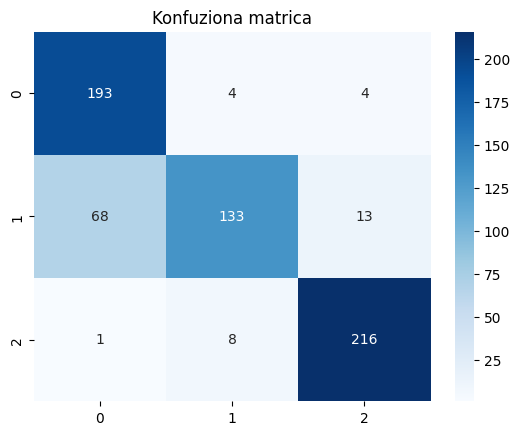

Tačnost klasifikacije je: 84.69%


In [101]:
# b) matrica konfuzije
cm = confusion_matrix(output_test,result_predicted)
plt.figure()
sns.heatmap(cm, annot=True, fmt='g', cmap="Blues")
plt.title('Konfuziona matrica')
plt.show()

# tačnost
accuracy = np.trace(cm) / np.sum(cm) *100
print(f"Tačnost klasifikacije je: {accuracy:.2f}%")

Histogram obeležja

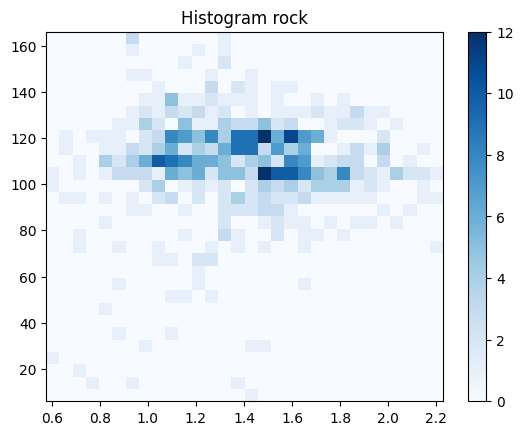

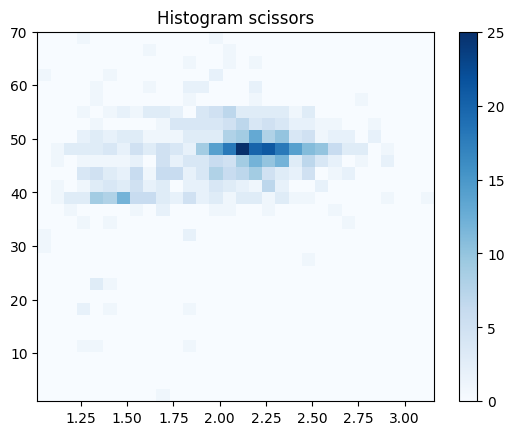

In [114]:
# v)
plt.figure()
plt.hist2d(rock_array[1,:], rock_array[2,:], bins=30, cmap='Blues')
plt.colorbar()
plt.title("Histogram rock")
plt.show()

plt.figure()
plt.hist2d(scissors_array[1,:], scissors_array[2,:], bins=30, cmap='Blues')
plt.colorbar()
plt.title("Histogram scissors")
plt.show()

Projektovanje parametarskog klasifikatora metodom resupstitucije

In [108]:
# procena parametara
rock_23 = rock_array[1:3, :]
scissors_23 = scissors_array[1:3, :]

M1_est = np.mean(rock_23, axis=1)       
M2_est = np.mean(scissors_23, axis=1)    

S1_est = np.cov(rock_23)       
S2_est = np.cov(scissors_23)    

# petlja po s i optimalnoj granici v0
s_vals = np.arange(0, 1, 0.001)
Neps_s = []
v0_opt = []

for s in s_vals:
    # na osnovu vrednosti s i procenjenih vrendosti odredimo parametar V, Y1 i Y2
    V = np.linalg.inv(s * S1_est + (1 - s) * S2_est) @ (M2_est - M1_est)
    Y1 = V.T @ rock_23         
    Y2 = V.T @ scissors_23   

    Y = np.sort(np.concatenate((Y1, Y2))) 
    n_total = len(Y)
    v0 = np.zeros(n_total - 1) # optimalna vrednost v0 za fiksno s
    Neps = np.zeros(n_total - 1) # optimalno N_epsilon za fiksno s

    for j in range(0,n_total - 1):
        v0[j] = -(Y[j] + Y[j + 1]) / 2 # granica je sr.vr. izmedju dve susedne tacke
        Neps[j] += np.sum(Y1 > -v0[j])   # greške iz klase rock
        Neps[j] += np.sum(Y2 < -v0[j])   # greške iz klase scissors

    # pamćenje najmanjeg broja grešaka i odgovarajuće vrednosti v0 u globalnim promenljivima
    Neps_s.append(np.min(Neps))
    v0_opt.append(v0[np.argmin(Neps)])

# pronalazak globalno najboljih vrednosti
i = np.argmin(Neps_s)
s_best = s_vals[i]
V_best = np.linalg.inv(s_best * S1_est + (1 - s_best) * S2_est) @ (M2_est - M1_est)
v0_best = v0_opt[i]


/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_9108/628261030.py:19: RuntimeWarning: divide by zero encountered in matmul
  Y1 = V.T @ rock_23
/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_9108/628261030.py:19: RuntimeWarning: overflow encountered in matmul
  Y1 = V.T @ rock_23
/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_9108/628261030.py:19: RuntimeWarning: invalid value encountered in matmul
  Y1 = V.T @ rock_23
/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_9108/628261030.py:20: RuntimeWarning: divide by zero encountered in matmul
  Y2 = V.T @ scissors_23
/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_9108/628261030.py:20: RuntimeWarning: overflow encountered in matmul
  Y2 = V.T @ scissors_23
/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_9108/628261030.py:20: RuntimeWarning: invalid value encountered in matmul
  Y2 = V.T @ scissors_23


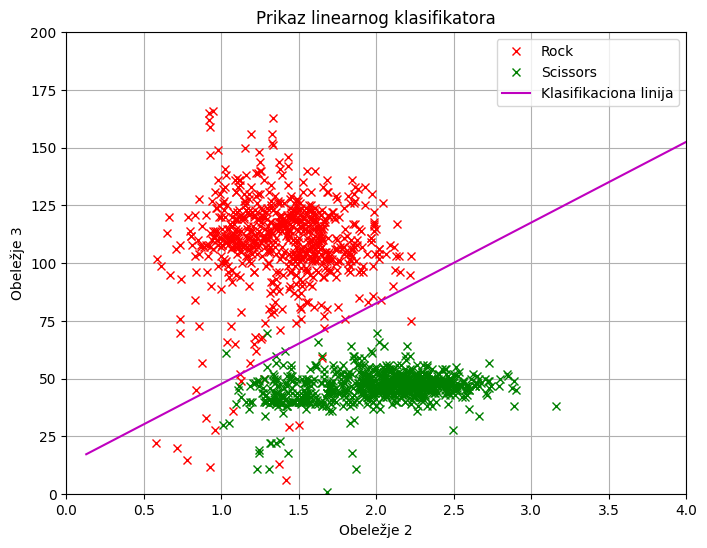

In [112]:
# iscrtavanje klasifikatora
a = V_best[0] 
b = V_best[1] 
c = v0_best            

x1_min = min(np.min(rock_array[0, :]), np.min(scissors_array[0, :]))
x1_max = max(np.max(rock_array[0, :]), np.max(scissors_array[0, :]))
x1 = np.linspace(x1_min, x1_max, 300)
x2 = -(a * x1 + c) / b

plt.figure(figsize=(8,6))
plt.plot(rock_array[1, :], rock_array[2, :], 'rx', label='Rock')
plt.plot(scissors_array[1, :], scissors_array[2, :], 'gx', label='Scissors')
plt.plot(x1, x2, 'm', label='Klasifikaciona linija')
plt.title('Prikaz linearnog klasifikatora')
plt.xlabel('Obeležje 2')
plt.ylabel('Obeležje 3')
plt.xlim([0,4])
plt.ylim([0,200])
plt.grid(True)
plt.legend()
plt.show()
